## Online Sales Analysis

## Part 1 — Data Loading

### Import required libraries

In [3]:
import pandas as pd
import matplotlib.pyplot as plt

### Load the CSV dataset using Pandas


In [5]:

df = pd.read_excel("C:/Users/ELCOT/Downloads/AEX/Project1/sales_data_2000_rows (2).xlsx")


### Display first 5 rows

In [6]:
df.head()

,Order_ID,Date,Product,Category,City,Quantity,Price
0,1001,2025-02-19,Printer,Electronics,Kolkata,3.0,9591
1,1002,2025-08-08,Pen,Stationery,Hyderabad,5.0,318
2,1003,2025-07-28,Mouse,Electronics,Chennai,1.0,697
3,1004,2025-08-15,Chair,Furniture,Ahmedabad,1.0,3410
4,1005,2025-04-12,Mouse,Electronics,Mumbai,NaN,624


### Check dataset information

In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Order_ID  2000 non-null   int64  
 1   Date      2000 non-null   str    
 2   Product   2000 non-null   str    
 3   Category  2000 non-null   str    
 4   City      2000 non-null   str    
 5   Quantity  1999 non-null   float64
 6   Price     2000 non-null   int64  
dtypes: float64(1), int64(2), str(4)
memory usage: 109.5 KB


### Check missing values

In [20]:
print(df.isnull().sum())

Order_ID    0
Date        0
Product     0
Category    0
City        0
Quantity    1
Price       0
dtype: int64


### Check duplicate records


In [12]:
df.duplicated().sum()


np.int64(0)

### Remove duplicate Records

In [22]:
 df.drop_duplicates()

,Order_ID,Date,Product,Category,City,Quantity,Price
0,1001,2025-02-19,Printer,Electronics,Kolkata,3.0,9591
1,1002,2025-08-08,Pen,Stationery,Hyderabad,5.0,318
2,1003,2025-07-28,Mouse,Electronics,Chennai,1.0,697
3,1004,2025-08-15,Chair,Furniture,Ahmedabad,1.0,3410
4,1005,2025-04-12,Mouse,Electronics,Mumbai,NaN,624
...,...,...,...,...,...,...,...
1995,2996,2025-12-26,Sofa,Furniture,Ahmedabad,4.0,15124
1996,2997,2025-02-27,Notebook,Stationery,Ahmedabad,3.0,160
1997,2998,2025-04-25,Chair,Furniture,Delhi,3.0,3590
1998,2999,2025-10-18,Monitor,Electronics,Mumbai,2.0,8550


### Correct spelling mistakes if any

In [24]:
from textblob import TextBlob

### Convert Date column into datetime format

In [26]:
df['Date']=pd.to_datetime(df['Date'])
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype         
---  ------    --------------  -----         
 0   Order_ID  2000 non-null   int64         
 1   Date      2000 non-null   datetime64[us]
 2   Product   2000 non-null   str           
 3   Category  2000 non-null   str           
 4   City      2000 non-null   str           
 5   Quantity  1999 non-null   float64       
 6   Price     2000 non-null   int64         
dtypes: datetime64[us](1), float64(1), int64(2), str(3)
memory usage: 109.5 KB


### Create a new column (Revenue = Quantity × Price)

In [3]:
df['Revenue'] = df['Quantity']*df['Price']
df.head()

,Order_ID,Date,Product,Category,City,Quantity,Price,Revenue
0,1001,2025-02-19,Printer,Electronics,Kolkata,3.0,9591,28773.0
1,1002,2025-08-08,Pen,Stationery,Hyderabad,5.0,318,1590.0
2,1003,2025-07-28,Mouse,Electronics,Chennai,1.0,697,697.0
3,1004,2025-08-15,Chair,Furniture,Ahmedabad,1.0,3410,3410.0
4,1005,2025-04-12,Mouse,Electronics,Mumbai,NaN,624,NaN


### Task 1 — Total Revenue


#### Total sales revenue of the company

In [7]:
total_revenue = df['Revenue'].sum()
print("Total Sales Revenue:",total_revenue)

Total Sales Revenue: 51500062.0



### Task 2 — Best Selling Product


In [8]:
best_product = df.groupby('Product')['Quantity'].sum().sort_values(ascending=False)

print(best_product.head(1))
print("\nBest Selling Product:", best_product.index[0])

Product
Chair    568.0
Name: Quantity, dtype: float64

Best Selling Product: Chair


### Task 3 — Best Performing City

In [9]:
best_city = df.groupby('City')['Revenue'].sum().sort_values(ascending=False)

print(best_city.head(1))
print("\nBest Performing City:", best_city.index[0])

City
Ahmedabad    7449911.0
Name: Revenue, dtype: float64

Best Performing City: Ahmedabad


### Task 4 — Category Analysis

#### :Revenue generated by each category

In [10]:
category_revenue = df.groupby('Category')['Revenue'].sum().sort_values(ascending=False)

print(category_revenue)

Category
Electronics    37093350.0
Furniture      13343784.0
Accessories      905769.0
Stationery       157159.0
Name: Revenue, dtype: float64


### Task 5 — Monthly Sales Analysis

#### Total revenue generated per month

In [ ]:
# 1. change the format
df['Date'] = pd.to_datetime(df['Date'])

# 2. change the date to month
df['Month'] = df['Date'].dt.to_period('M')

# 3. Month wise Revenue
monthly_revenue = df.groupby('Month')['Revenue'].sum()

print(monthly_revenue)

Month
2025-01    4021909.0
2025-02    3655339.0
2025-03    4607846.0
2025-04    4783602.0
2025-05    4884091.0
2025-06    3654206.0
2025-07    3979183.0
2025-08    4012286.0
2025-09    4318017.0
2025-10    4428577.0
2025-11    4185989.0
2025-12    4891185.0
2026-01      77832.0
Freq: M, Name: Revenue, dtype: float64


### Part 6 — Data Visualization

#### Bar Chart -Revenue by City


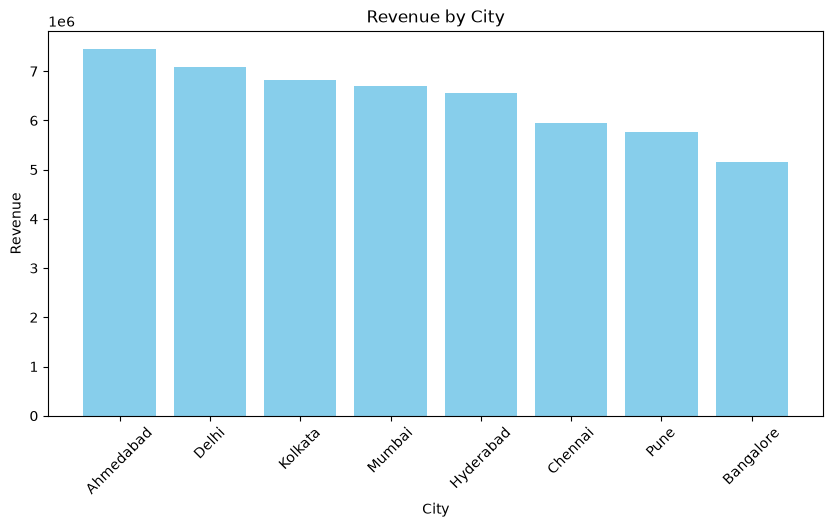

In [12]:
city_revenue = df.groupby('City')['Revenue'].sum().sort_values(ascending=False)

plt.figure(figsize=(10, 5))
plt.bar(city_revenue.index, city_revenue.values, color='skyblue')
plt.title('Revenue by City')
plt.xlabel('City')
plt.ylabel('Revenue')
plt.xticks(rotation=45)
plt.show()

#### Pie Chart- Category contribution

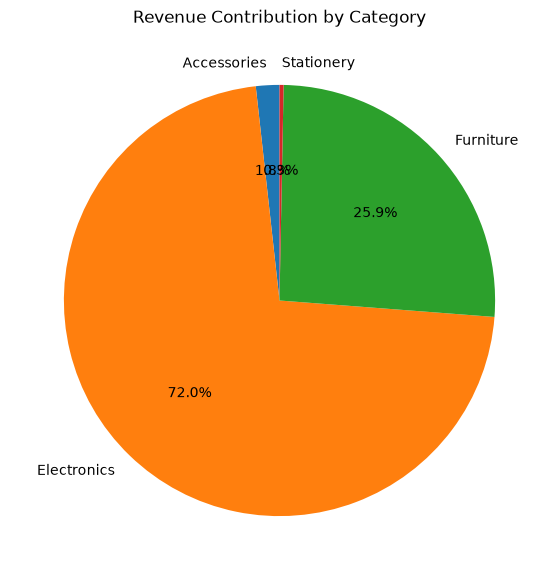

In [13]:
category_revenue = df.groupby('Category')['Revenue'].sum()

plt.figure(figsize=(7, 7))
plt.pie(category_revenue.values, labels=category_revenue.index, autopct='%1.1f%%', startangle=90)
plt.title('Revenue Contribution by Category')
plt.show()


#### Line Chart-  Monthly sales trend

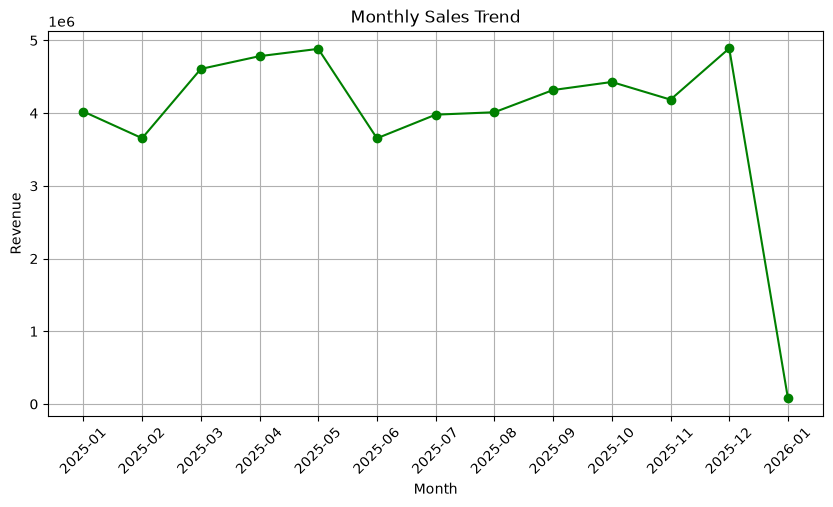

In [14]:
monthly_revenue = df.groupby('Month')['Revenue'].sum()

plt.figure(figsize=(10, 5))
plt.plot(monthly_revenue.index.astype(str), monthly_revenue.values, marker='o', color='green')
plt.title('Monthly Sales Trend')
plt.xlabel('Month')
plt.ylabel('Revenue')
plt.xticks(rotation=45)
plt.grid(True)
plt.show()

### Part 7 — Business Insights

#### Students must write minimum 5 insights from the analysis.

In [10]:
df['Revenue'] = df['Quantity'] * df['Price']

print("Total:", df['Revenue'].sum())
print("Electronics %:", df[df['Category']=='Electronics']['Revenue'].sum() / df['Revenue'].sum() * 100)
print("Chair Qty:", df[df['Product']=='Chair']['Quantity'].sum())
print(df.groupby('City')['Revenue'].sum().sort_values(ascending=False))

Total: 51500062.0
Electronics %: 72.02583561938236
Chair Qty: 568.0
City
Ahmedabad    7449911.0
Delhi        7092644.0
Kolkata      6819173.0
Mumbai       6702803.0
Hyderabad    6565333.0
Chennai      5944069.0
Pune         5764738.0
Bangalore    5161391.0
Name: Revenue, dtype: float64


### Part 8 — Recommendations

#### Students must provide minimum 3 business recommendations.

#### 1. Focus on Electronics

 Electronics contributes 72% of total revenue (Rs. 3.70 Cr). 
More stock, offers and advertisements should be focused on this category.

#### 2. Promote Chair Product


Chair is the best-selling product with 568 units sold.
 Special offers and promotions for Chair will further increase sales.

#### 3. Improve Sales in Bangalore, Pune and Chennai


Ahmedabad is the top city with Rs. 74.4 Lakhs revenue. Sales are low in Bangalore, Pune and Chennai.
 Marketing should be improved in these cities.

#### 4. Give Discounts in June and February


Sales were high in May and December, but low in June (Rs. 35 Lakhs) and February (Rs. 36 Lakhs).
 Discounts and festival offers during June and February will help balance monthly revenue.

#### 5. Improve Stationery and Accessories

Stationery contributes only 0.3% and Accessories only 1.8% of total revenue. They should be offered as combo offers with Electronics products to increase their sales.

#### 6. Create Furniture Bundle Offers


Furniture is the second largest category with 25.9% revenue (Rs. 1.33 Cr). Bundle offers like Chair + Table with a small discount will increase Furniture sales.

#### 7. Retain Customers in Top Cities


Ahmedabad, Delhi and Kolkata are the top cities for revenue. Fast delivery, loyalty offers and good customer service in these cities will help retain customers and get repeat orders